In [176]:
import numpy as np
import pandas as pd
from utils import *
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import pairwise_distances

In [61]:
df_spectra_flopp = pd.read_csv('../processed_data/flopp_flopp_e_pivot.csv')
del df_spectra_flopp['Unnamed: 0']

label_table = (
    df_spectra_flopp.
    query('data_source == "flopp"').
    groupby(['polymer']).
    count()['file_name'].
    reset_index().
    reset_index().
    iloc[:,:-1])

label_table_e = (
    df_spectra_flopp.
    query('data_source == "flopp_e"').
    groupby(['polymer']).
    count()['file_name'].
    reset_index().
    reset_index().
    iloc[:,:-1])

label_table = label_table.merge(label_table_e, on='polymer', how='left')
label_table = label_table.drop(np.where(label_table['polymer'] == 'Polyethylene Adipate')[0][0], axis=0)

del label_table['index_x']
del label_table['index_y']
label_table = label_table.reset_index()
label_table.columns = ['label', 'polymer']
polymer_10_more = ['Cotton', 'Polyethylene', 'Polyethylene Terephthalate','Polypropylene', 'Polystyrene']
label_table = label_table.reset_index(drop=True)

label_table_adaptive = label_table.query('polymer in @polymer_10_more')

label_table['label'] = np.arange(label_table.shape[0])
label_table_adaptive['label'] = np.arange(label_table_adaptive.shape[0])

df_spectra_flopp_adaptive = df_spectra_flopp.merge(label_table_adaptive)
df_spectra_flopp = df_spectra_flopp.merge(label_table)
wl_list = np.float64(df_spectra_flopp.columns[3:-1])

y_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,1].to_numpy()
label_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,-1].to_numpy()
X_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,3:-1].to_numpy()
X_train = (X_train - X_train.mean(1)[:, None]) / X_train.std(1)[:, None]

y_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,1].to_numpy()
label_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,-1].to_numpy()
X_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,3:-1].to_numpy()
X_test = (X_test - X_test.mean(1)[:, None]) / X_test.std(1)[:, None]


y_train_a = df_spectra_flopp_adaptive.query('data_source == "flopp"').iloc[:,1].to_numpy()
label_train_a = df_spectra_flopp_adaptive.query('data_source == "flopp"').iloc[:,-1].to_numpy()
X_train_a = df_spectra_flopp_adaptive.query('data_source == "flopp"').iloc[:,3:-1].to_numpy()
X_train_a = (X_train_a - X_train_a.mean(1)[:, None]) / X_train_a.std(1)[:, None]

y_test_a = df_spectra_flopp_adaptive.query('data_source == "flopp_e"').iloc[:,1].to_numpy()
label_test_a = df_spectra_flopp_adaptive.query('data_source == "flopp_e"').iloc[:,-1].to_numpy()
X_test_a = df_spectra_flopp_adaptive.query('data_source == "flopp_e"').iloc[:,3:-1].to_numpy()
X_test_a = (X_test_a - X_test_a.mean(1)[:, None]) / X_test_a.std(1)[:, None]


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_28761/1347792697.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  label_table_adaptive['label'] = np.arange(label_table_adaptive.shape[0])


In [265]:
coefs = []
accs = []
C = [2,3,4,5,10,20,30,40,100,200,300]
C = np.concatenate([np.linspace(0.01,1, 10), np.array(C)])
for c in C:
    clf = LogisticRegression(random_state=0, C=c, penalty='l1', solver='saga')
    clf.fit(X_train, y_train)
    accs.append(clf.score(X_test, y_test))
    #accs.append(pd.DataFrame({'polymer':y_test,'acc':clf.predict(X_test)==y_test}).groupby('polymer').mean()['acc'].to_numpy())
    coefs.append(clf.coef_)

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not c

Acrylic 1723


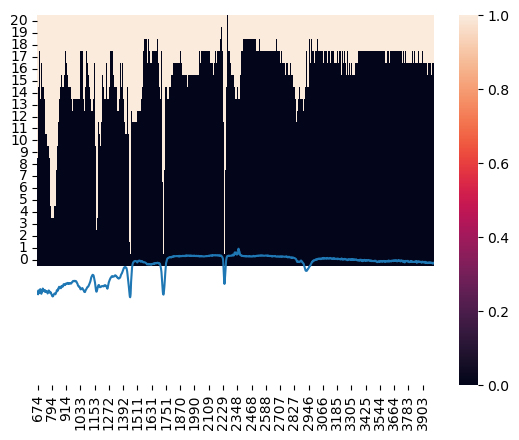

Acrylonitrile Butadiene Styrene 1701


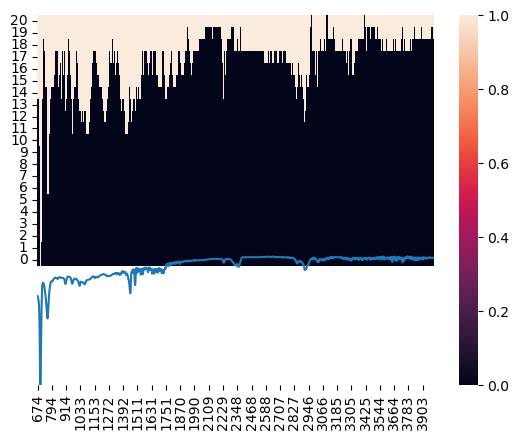

Cotton 1722


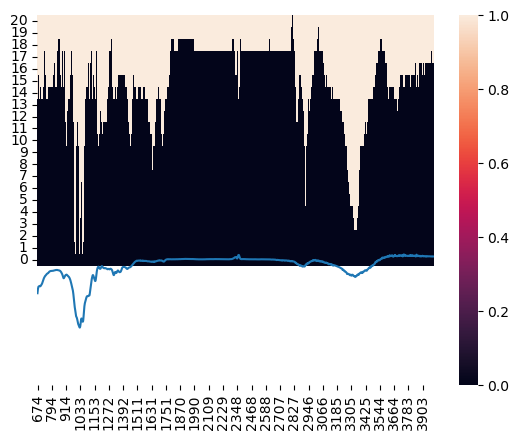

Polyamide 1716


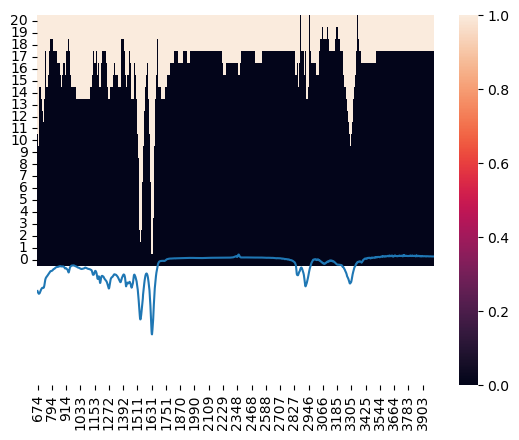

Polycarbonate 1416


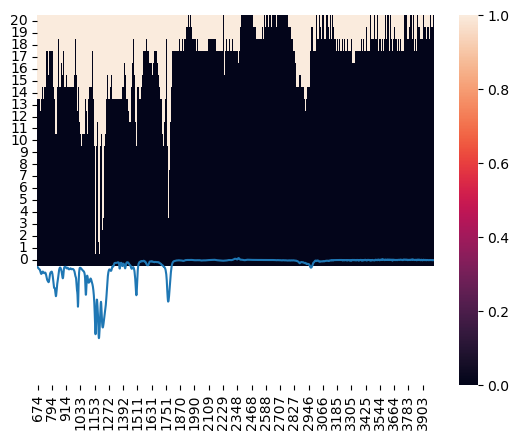

Polyethylene 1629


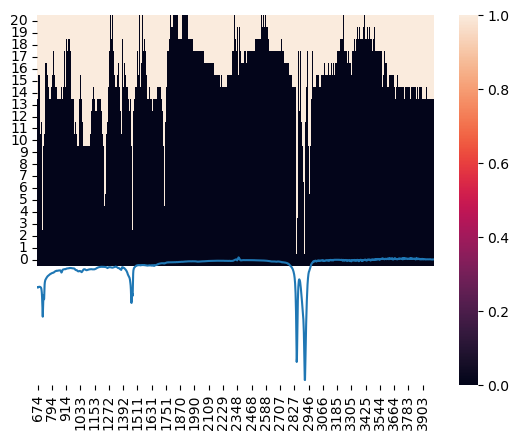

Polyethylene Terephthalate 1683


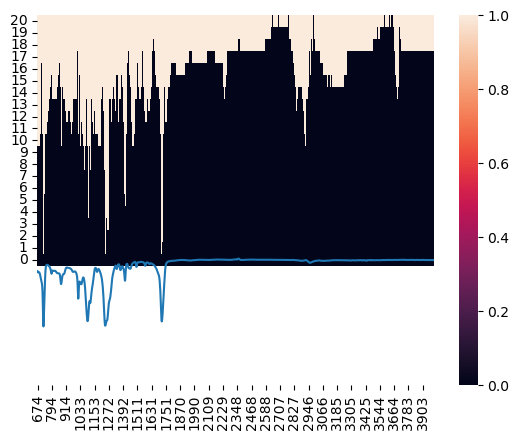

Polyethylene Vinyl Acetate 1556


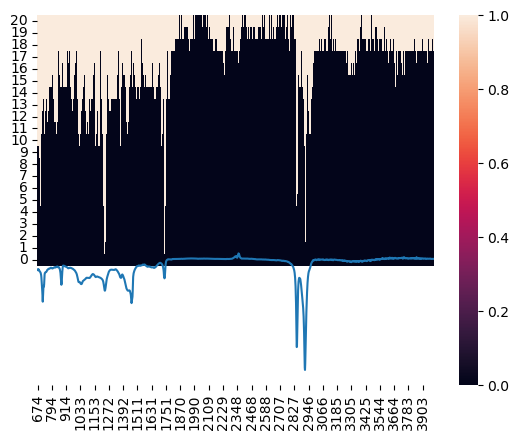

Polylactic acid 1541


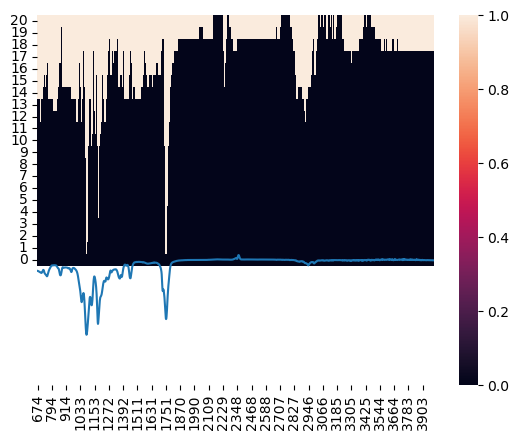

Polypropylene 1641


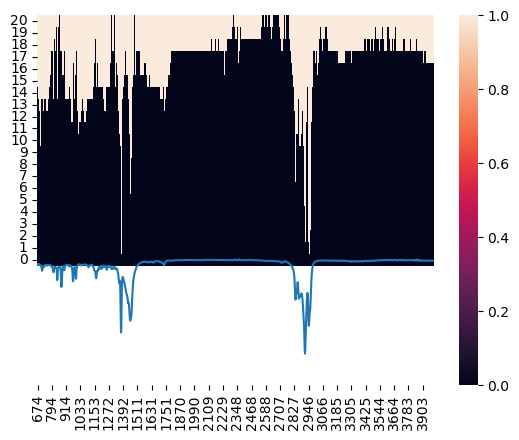

Polystyrene 1637


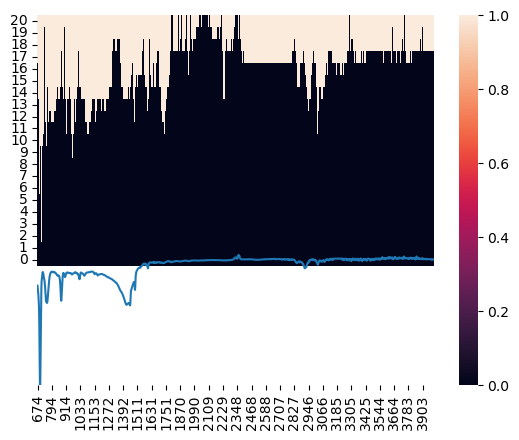

Polyurethane 1714


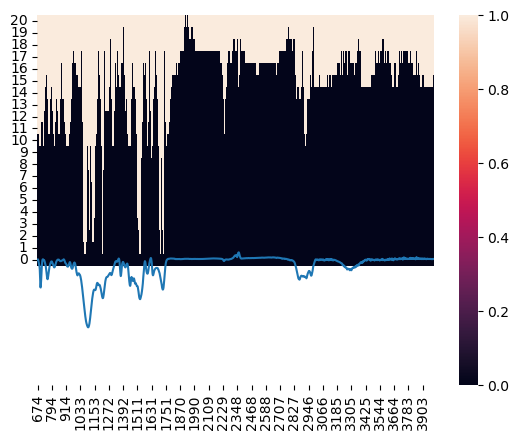

Polyvinyl Chloride 1716


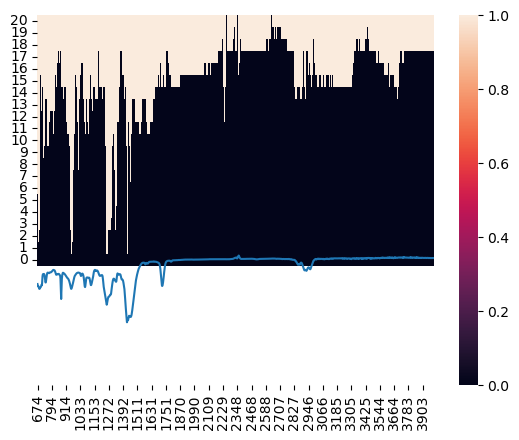

Rubber 1725


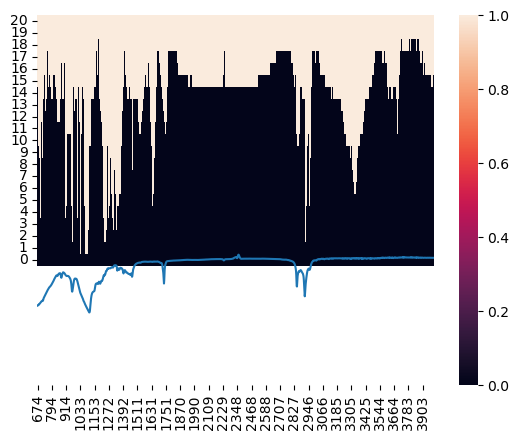

In [266]:
for i in range(14):
    coefs_ = np.concatenate([coef[i][None,:] for coef in coefs],0)
    coefs_ = np.int64(np.abs(coefs_) > 0)
    coefs_ = pd.DataFrame(coefs_)
    coefs_.columns = np.int64(wl_list)
    #print(label_table.iloc[i,1], coefs_.sum(1)[np.argmax(accs)])
    print(label_table.iloc[i,1], np.max(coefs_.sum(1)))
    
    sns.heatmap(np.abs(coefs_) > 0)
    plt.plot(X_train[y_train == label_table.iloc[i,1]][0,:])
    plt.ylim(-10, C.shape[0])
    plt.show()

In [257]:
clf.classes_

array(['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton',
       'Polyamide', 'Polycarbonate', 'Polyethylene',
       'Polyethylene Terephthalate', 'Polyethylene Vinyl Acetate',
       'Polylactic acid', 'Polypropylene', 'Polystyrene', 'Polyurethane',
       'Polyvinyl Chloride', 'Rubber'], dtype=object)

In [258]:
(coefs[1])[5, :]<0

array([False, False, False, ..., False, False, False])

In [259]:
(np.argmax(smx[label_test == i,:], 1) == i).mean()

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_28761/2775857973.py:1: RuntimeWarning: Mean of empty slice.
  (np.argmax(smx[label_test == i,:], 1) == i).mean()
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/numpy/core/_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


nan

In [341]:
idx_ft = (np.abs(coefs[1]) > 0)[5, :]
idx_ft

array([False, False, False, ..., False, False, False])

In [330]:
smx_list = []
for i in range(X_train.shape[0]):
    smx_ = smx_hqi(np.delete(X_train, i, 0), X_train[i:(i+1),:], np.delete(label_train, i, 0))
    smx_list.append(smx_)

smx = np.concatenate(smx_list, 0)

In [331]:
(np.argmax(smx, 1) == label_train).mean()

0.9402173913043478

In [342]:
smx_list_2 = []
for k in range(X_train.shape[0]):
    smx_ = smx_hqi(np.delete(X_train, k, 0), X_train[k:(k+1),:], np.delete(label_train, k, 0))
    smx_list_2.append(smx_)

smx_2 = np.concatenate(smx_list_2, 0)
        
for j in range(1, C.shape[0]):
    better_perf = []
    eq_perf = []
    acc_ = []
    for i in range(14):
        #if (label_test == i).sum() == 0:
        #    continue
        idx_ft = (np.abs(coefs[j]) > 0)[i, :]
        
        #smx_2 = smx_hqi(X_train, X_train, label_train)
        #smx_1 = smx_hqi(X_train[:, idx_ft], X_test[:, idx_ft], label_train)
        
        smx_list_1 = []
        for k in range(X_train.shape[0]):
            smx_ = smx_hqi(np.delete(X_train[:,idx_ft], k, 0), X_train[k:(k+1),idx_ft], np.delete(label_train, k, 0))
            smx_list_1.append(smx_)

        smx_1 = np.concatenate(smx_list_1, 0)
        
        
        #print(label_table.iloc[i,1],
        #      (np.argmax(smx_2[label_test == i,:], 1) == i).mean(),
        #      (np.argmax(smx_1[label_test == i,:], 1) == i).mean())
        better_perf.append((np.argmax(smx_2[label_train == i,:], 1) == i).mean() < (np.argmax(smx_1[label_train == i,:], 1) == i).mean())
        eq_perf.append((np.argmax(smx_2[label_train == i,:], 1) == i).mean() == (np.argmax(smx_1[label_train == i,:], 1) == i).mean())
        acc_.append((np.argmax(smx_1[label_train == i,:], 1) == i).sum())
    
    print(j, 
          int(100*np.mean(better_perf)), 
          int(100*np.mean(eq_perf)), 
          int(100*(np.mean(better_perf) + np.mean(eq_perf))),
          int(100*np.sum(acc_)/smx_1.shape[0]))


1 7 35 42 76
2 7 42 50 85
3 14 50 64 88
4 21 42 64 89
5 14 57 71 89
6 14 57 71 90
7 21 57 78 91
8 28 50 78 94
9 28 57 85 94
10 21 64 85 94
11 21 71 92 95
12 21 71 92 95
13 21 71 92 95
14 14 78 92 95
15 21 78 100 96
16 21 78 100 95
17 14 85 100 95
18 0 100 100 94
19 0 100 100 94
20 0 100 100 94


In [285]:
smx_2 = smx_hqi(X_train, X_test, label_train)
for j in range(1, C.shape[0]):
    better_perf = []
    eq_perf = []
    acc_ = []
    for i in range(14):
        if (label_test == i).sum() == 0:
            continue
        idx_ft = (np.abs(coefs[j]) > 0)[i, :]        
        smx_1 = smx_hqi(X_train[:, idx_ft], X_test[:, idx_ft], label_train)
        #print(label_table.iloc[i,1],
        #      (np.argmax(smx_2[label_test == i,:], 1) == i).mean(),
        #      (np.argmax(smx_1[label_test == i,:], 1) == i).mean())
        better_perf.append((np.argmax(smx_2[label_test == i,:], 1) == i).mean() < (np.argmax(smx_1[label_test == i,:], 1) == i).mean())
        eq_perf.append((np.argmax(smx_2[label_test == i,:], 1) == i).mean() == (np.argmax(smx_1[label_test == i,:], 1) == i).mean())
        acc_.append((np.argmax(smx_1[label_test == i,:], 1) == i).sum())
    
    print(j, 
          int(100*np.mean(better_perf)), 
          int(100*np.mean(eq_perf)), 
          int(100*np.mean(better_perf) + np.mean(eq_perf)),
          int(100*np.sum(acc_)/smx_1.shape[0]))


1 9 27 9 73
2 36 27 36 84
3 18 45 18 83
4 27 36 27 88
5 36 27 36 91
6 27 36 27 91
7 36 27 36 92
8 27 45 27 92
9 36 45 36 94
10 27 63 27 93
11 36 54 36 91
12 27 63 27 87
13 36 54 36 88
14 36 63 37 87
15 36 63 37 86
16 36 63 37 86
17 27 63 27 84
18 18 72 18 82
19 0 90 0 81
20 0 100 1 82


<AxesSubplot: >

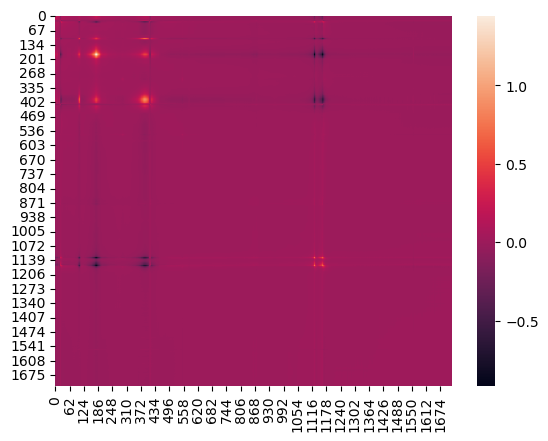

In [451]:
cov_mats = [np.cov(X_train[label_train == i, :].T) for i in range(14)]
sns.heatmap(cov_mats[5])

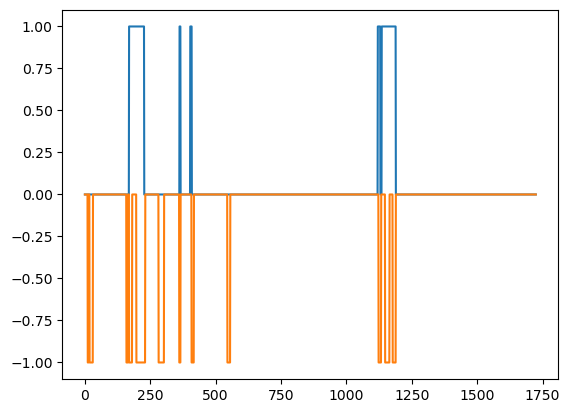

In [436]:
plt.plot((np.diag(cov_mat) > .5)*1)
plt.plot(((np.abs(coefs[11]) > 0)[5, :])*(-1))

In [405]:
smx = smx_hqi(X_train, X_test, label_train)
for j in range(1, C.shape[0]):
    smx_1 = np.zeros(smx.shape)
    for i in range(14):
        idx_ft = (np.abs(coefs[j]) > 0)[i, :]        
        smx_1[:,i] = smx_hqi(X_train[:, idx_ft], X_test[:, idx_ft], label_train)[:,i]

    print(j,(np.argmax(smx, 1) == label_test).mean(), (np.argmax(smx_1, 1) == label_test).mean())

1 0.8201058201058201 0.13227513227513227
2 0.8201058201058201 0.5026455026455027
3 0.8201058201058201 0.5767195767195767
4 0.8201058201058201 0.5925925925925926
5 0.8201058201058201 0.8042328042328042
6 0.8201058201058201 0.8412698412698413
7 0.8201058201058201 0.8306878306878307
8 0.8201058201058201 0.8359788359788359
9 0.8201058201058201 0.8306878306878307
10 0.8201058201058201 0.8571428571428571
11 0.8201058201058201 0.8835978835978836
12 0.8201058201058201 0.8571428571428571
13 0.8201058201058201 0.8571428571428571
14 0.8201058201058201 0.8677248677248677
15 0.8201058201058201 0.8359788359788359
16 0.8201058201058201 0.8359788359788359
17 0.8201058201058201 0.8253968253968254
18 0.8201058201058201 0.8201058201058201
19 0.8201058201058201 0.8148148148148148
20 0.8201058201058201 0.8148148148148148


In [479]:
smx = smx_hqi(X_train, X_test, label_train)
for j in range(1, C.shape[0]):
    smx_1 = np.zeros(smx.shape)
    for i in range(14):
        
        ps = 1-np.array([(np.abs(coefs[j]) > 0)[i, :].sum() for i in range(14)]) / 1725
        qs = [np.quantile(np.diag(cov_mats[i]), ps[i]) for i in range(14)]
        idx_cov = np.diag(cov_mats[i]) > qs[i]
        #idx_ft = (np.abs(coefs[j]) > 0)[i, :]        
        smx_1[:,i] = smx_hqi(X_train[:, idx_cov], X_test[:, idx_cov], label_train)[:,i]

    print(j,(np.argmax(smx, 1) == label_test).mean(), (np.argmax(smx_1, 1) == label_test).mean())

1 0.8201058201058201 0.2804232804232804
2 0.8201058201058201 0.5873015873015873
3 0.8201058201058201 0.582010582010582
4 0.8201058201058201 0.7619047619047619
5 0.8201058201058201 0.8201058201058201
6 0.8201058201058201 0.8095238095238095
7 0.8201058201058201 0.8253968253968254
8 0.8201058201058201 0.8148148148148148
9 0.8201058201058201 0.8253968253968254
10 0.8201058201058201 0.8465608465608465
11 0.8201058201058201 0.8465608465608465
12 0.8201058201058201 0.8465608465608465
13 0.8201058201058201 0.8624338624338624
14 0.8201058201058201 0.8359788359788359
15 0.8201058201058201 0.8148148148148148
16 0.8201058201058201 0.8148148148148148
17 0.8201058201058201 0.8148148148148148
18 0.8201058201058201 0.8148148148148148
19 0.8201058201058201 0.8148148148148148
20 0.8201058201058201 0.8148148148148148


In [413]:
smx_list = []
for i in range(X_train.shape[0]):
    smx_ = smx_hqi(np.delete(X_train, i, 0), X_train[i:(i+1),:], np.delete(label_train, i, 0))
    smx_list.append(smx_)

smx = np.concatenate(smx_list, 0)

for j in range(1, C.shape[0]):
    smx_1 = np.zeros(smx.shape)
    for i in range(14):
        idx_ft = (np.abs(coefs[j]) > 0)[i, :]       
        smx_list_1 = []

        for k in range(X_train.shape[0]):
            smx_ = smx_hqi(np.delete(X_train[:,idx_ft], k, 0), X_train[k:(k+1),idx_ft], np.delete(label_train, k, 0))
            smx_list_1.append(smx_)

        smx_1_ = np.concatenate(smx_list_1, 0)

        smx_1[:,i] = smx_1_[:,i]

    print(j,(np.argmax(smx, 1) == label_train).mean(), (np.argmax(smx_1, 1) == label_train).mean())

1 0.9402173913043478 0.18478260869565216
2 0.9402173913043478 0.6467391304347826
3 0.9402173913043478 0.7608695652173914
4 0.9402173913043478 0.7934782608695652
5 0.9402173913043478 0.8260869565217391
6 0.9402173913043478 0.8532608695652174
7 0.9402173913043478 0.8641304347826086
8 0.9402173913043478 0.875
9 0.9402173913043478 0.8804347826086957
10 0.9402173913043478 0.9402173913043478
11 0.9402173913043478 0.9456521739130435
12 0.9402173913043478 0.9510869565217391
13 0.9402173913043478 0.9510869565217391
14 0.9402173913043478 0.9565217391304348
15 0.9402173913043478 0.9619565217391305
16 0.9402173913043478 0.9619565217391305
17 0.9402173913043478 0.9565217391304348
18 0.9402173913043478 0.9456521739130435
19 0.9402173913043478 0.9402173913043478
20 0.9402173913043478 0.9402173913043478


In [280]:
better_perf = []
for i in range(14):
    if (label_test == i).sum() == 0:
        continue
    idx_ft = (np.abs(coefs[9]) > 0)[i, :]
    smx_2 = smx_hqi(X_train, X_test, label_train)
    smx_1 = smx_hqi(X_train[:, idx_ft], X_test[:, idx_ft], label_train)
    print(label_table.iloc[i,1],
          (np.argmax(smx_2[label_test == i,:], 1) == i).mean(),
          (np.argmax(smx_1[label_test == i,:], 1) == i).mean())
    better_perf.append((np.argmax(smx_2[label_test == i,:], 1) == i).mean() <= (np.argmax(smx_1[label_test == i,:], 1) == i).mean())
np.mean(better_perf)

Acrylonitrile Butadiene Styrene 1.0 1.0
Cotton 0.9166666666666666 0.9166666666666666
Polyamide 1.0 0.8333333333333334
Polycarbonate 1.0 1.0
Polyethylene 0.7551020408163265 0.9387755102040817
Polyethylene Terephthalate 1.0 1.0
Polyethylene Vinyl Acetate 0.6 1.0
Polypropylene 0.7727272727272727 0.9848484848484849
Polystyrene 0.75 0.9166666666666666
Polyurethane 1.0 0.6666666666666666
Polyvinyl Chloride 0.8888888888888888 0.8888888888888888


0.8181818181818182

In [347]:
smx_list_2 = []
for k in range(X_train.shape[0]):
    smx_ = smx_nn(np.delete(X_train, k, 0), X_train[k:(k+1),:], np.delete(label_train, k, 0))
    smx_list_2.append(smx_)

smx_2 = np.concatenate(smx_list_2, 0)
        
for j in range(1, C.shape[0]):
    better_perf = []
    eq_perf = []
    acc_ = []
    for i in range(14):
        #if (label_test == i).sum() == 0:
        #    continue
        idx_ft = (np.abs(coefs[j]) > 0)[i, :]
        
        #smx_2 = smx_hqi(X_train, X_train, label_train)
        #smx_1 = smx_hqi(X_train[:, idx_ft], X_test[:, idx_ft], label_train)
        
        smx_list_1 = []
        for k in range(X_train.shape[0]):
            smx_ = smx_nn(np.delete(X_train[:,idx_ft], k, 0), X_train[k:(k+1),idx_ft], np.delete(label_train, k, 0))
            smx_list_1.append(smx_)

        smx_1 = np.concatenate(smx_list_1, 0)
        
        
        #print(label_table.iloc[i,1],
        #      (np.argmax(smx_2[label_test == i,:], 1) == i).mean(),
        #      (np.argmax(smx_1[label_test == i,:], 1) == i).mean())
        better_perf.append((np.argmax(smx_2[label_train == i,:], 1) == i).mean() < (np.argmax(smx_1[label_train == i,:], 1) == i).mean())
        eq_perf.append((np.argmax(smx_2[label_train == i,:], 1) == i).mean() == (np.argmax(smx_1[label_train == i,:], 1) == i).mean())
        acc_.append((np.argmax(smx_1[label_train == i,:], 1) == i).sum())
    
    print(j, 
          int(100*np.mean(better_perf)), 
          int(100*np.mean(eq_perf)), 
          int(100*(np.mean(better_perf) + np.mean(eq_perf))),
          int(100*np.sum(acc_)/smx_1.shape[0]))


1 0 64 64 91
2 7 78 85 93
3 7 71 78 92
4 7 85 92 94
5 7 92 100 94
6 7 92 100 94
7 14 85 100 95
8 14 85 100 95
9 14 85 100 95
10 21 78 100 95
11 21 78 100 96
12 21 78 100 96
13 21 78 100 96
14 21 78 100 96
15 21 78 100 96
16 21 78 100 95
17 14 85 100 95
18 0 100 100 94
19 0 100 100 94
20 0 100 100 94


In [343]:
for j in range(1, C.shape[0]):
    better_perf = []
    eq_perf = []
    acc_ = []
    for i in range(14):
        if (label_test == i).sum() == 0:
            continue
        idx_ft = (np.abs(coefs[j]) > 0)[i, :]
        smx_2 = smx_nn(X_train, X_test, label_train)
        smx_1 = smx_nn(X_train[:, idx_ft], X_test[:, idx_ft], label_train)
        #print(label_table.iloc[i,1],
        #      (np.argmax(smx_2[label_test == i,:], 1) == i).mean(),
        #      (np.argmax(smx_1[label_test == i,:], 1) == i).mean())
        better_perf.append((np.argmax(smx_2[label_test == i,:], 1) == i).mean() < (np.argmax(smx_1[label_test == i,:], 1) == i).mean())
        eq_perf.append((np.argmax(smx_2[label_test == i,:], 1) == i).mean() == (np.argmax(smx_1[label_test == i,:], 1) == i).mean())
        acc_.append((np.argmax(smx_1[label_test == i,:], 1) == i).sum())
    
    print(j, 
          int(100*np.mean(better_perf)), 
          int(100*np.mean(eq_perf)), 
          int(100*np.mean(better_perf) + np.mean(eq_perf)),
          int(100*np.sum(acc_)/smx_1.shape[0]))


1 27 72 27 87
2 27 63 27 86
3 27 54 27 86
4 36 63 37 88
5 36 63 37 91
6 36 63 37 91
7 36 63 37 91
8 36 63 37 91
9 36 63 37 91
10 27 54 27 85
11 27 54 27 84
12 27 63 27 83
13 27 63 27 83
14 27 63 27 83
15 36 63 37 85
16 27 72 27 85
17 27 72 27 85
18 0 100 1 82
19 0 100 1 82
20 0 100 1 82


In [346]:
smx = smx_nn(X_train, X_test, label_train)
(np.argmax(smx, 1) == label_test).mean()

0.8201058201058201

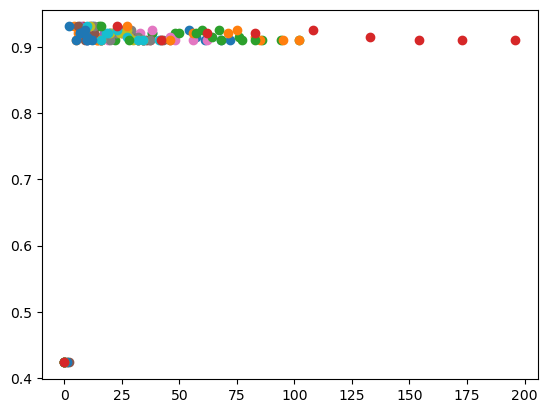

In [157]:
for i in range(14):
    coefs_ = np.concatenate([coef[i][None,:] for coef in coefs],0)
    coefs_ = np.int64(np.abs(coefs_) > 0)
    coefs_ = pd.DataFrame(coefs_)
    coefs_.columns = np.int64(wl_list)

    plt.scatter(list(coefs_.sum(1)), accs)